# Inteligência de Dados na Segurança Pública: Análise da Violência Doméstica (MG)

## 1. Contexto e Visão Executiva
A formulação de políticas públicas eficazes exige a transição do empirismo para a gestão baseada em evidências. Este projeto analisa a evolução temporal e espacial da violência doméstica no estado de Minas Gerais (2014-2023), utilizando técnicas avançadas de Engenharia e Ciência de Dados. 

O objetivo não é apenas relatar o passado, mas extrair inteligência acionável: identificar gargalos de subnotificação, mapear o ciclo de escalada da violência e construir modelagem preditiva matematicamente fundamentada para auxiliar a tomada de decisão na alocação de recursos preventivos.

## 2. Hipóteses de Negócio
A análise investigativa foi estruturada para validar ou refutar as seguintes premissas:
* **H1 (Histórico e Subnotificação):** O volume de vítimas apresenta crescimento constante, mas sofreu anomalias estatísticas severas (subnotificação) em períodos recentes.
* **H2 (Densidade Demográfica):** A Região Metropolitana (RMBH) concentra a maior densidade absoluta de ocorrências frente ao interior do estado.
* **H3 (Ciclo da Violência):** Crimes de menor potencial ofensivo (Ameaças) e infrações judiciais (Quebra de Medida Protetiva) são preditores matemáticos diretos do volume de Lesões Corporais em um município.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy as sqla
from pathlib import Path
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
import warnings
warnings.filterwarnings('ignore')

import sys

project_root = Path.cwd()
if not (project_root / "src").exists():
    if (project_root.parent / "src").exists():
        project_root = project_root.parent
    else:
        raise FileNotFoundError("Não foi possível localizar o pacote 'src' no diretório atual ou no diretório pai.")

sys.path.insert(0, str(project_root))

from src.etl_builder import pipeline_etl
from src.custom_ridge import treinar_ridge_numpy

plt.style.use("ggplot")
plt.rcParams.update({'figure.figsize': (10, 6), 'font.size': 11, 'figure.dpi': 100})

BASE_DIR = project_root
CSV_DIR = BASE_DIR / 'data'
DB_PATH = BASE_DIR / 'violencia_mg.sqlite'

db_engine = pipeline_etl(CSV_DIR, DB_PATH)

db_engine = sqla.create_engine(f"sqlite:///{DB_PATH}")

## 4. Análise Exploratória de Dados (EDA)

Com o banco de dados normalizado em tabelas Fato e Dimensão, utilizamos a linguagem SQL para agregar métricas de forma otimizada antes de transferi-las para a memória do Pandas.

### Validação da Hipótese 1: Evolução Histórica

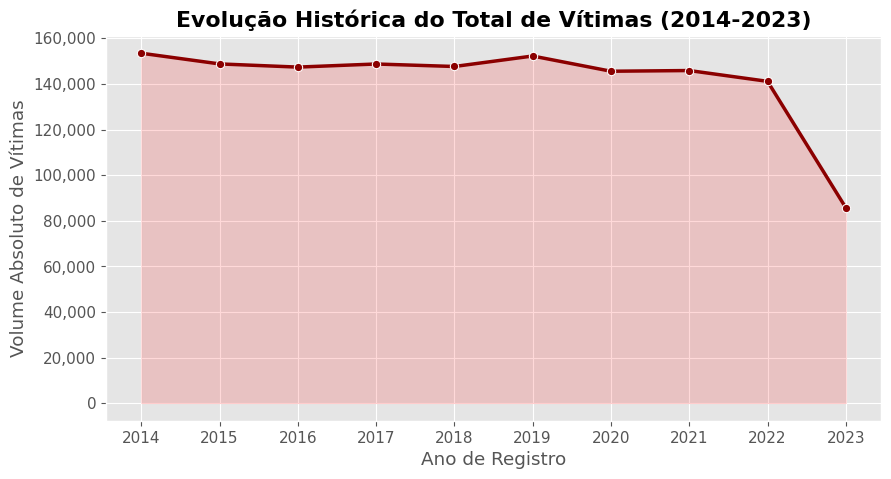

In [11]:
query_h1 = """
SELECT ano, SUM(qtde_vitimas) as total_vitimas 
FROM Fato_Ocorrencia 
GROUP BY ano 
ORDER BY ano
"""
df_evolucao = pd.read_sql(query_h1, db_engine)

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_evolucao, x='ano', y='total_vitimas', marker='o', color='#8B0000', linewidth=2.5)
plt.fill_between(df_evolucao['ano'], df_evolucao['total_vitimas'], alpha=0.15, color='red')
plt.title("Evolução Histórica do Total de Vítimas (2014-2023)", weight='bold')
plt.xlabel("Ano de Registro")
plt.ylabel("Volume Absoluto de Vítimas")
plt.xticks(df_evolucao['ano'])
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
plt.show()

#### Interpretação

A série temporal é um eletrocardiograma quase morto na casa das 150 mil vítimas até o ano de 2022. O desfiladeiro absurdo para a casa das 80 mil ocorrências em 2023 não é um milagre da paz mundial nem eficácia de gestão. Na vida real, isso é pura e simples incompetência na consolidação dos dados por parte das delegacias antes do fechamento da base estatística. A Hipótese 1 está validada: a subnotificação recente é grosseira e impede qualquer uso do ano de 2023 para treinar modelos preditivos sem causar um viés catastrófico.

### Validação da Hipótese 2: Capital vs. Interior

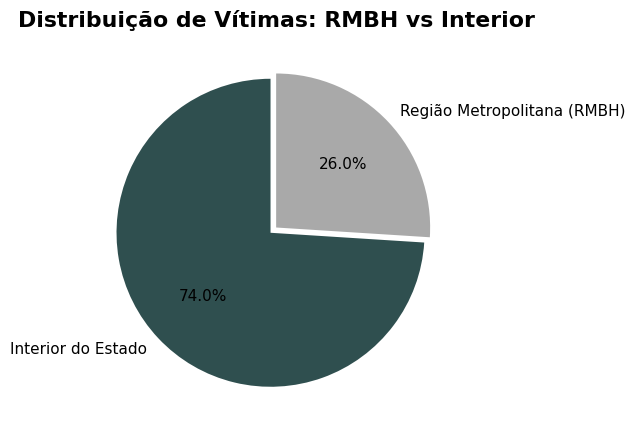

In [12]:
query_h2 = """
SELECT 
    CASE WHEN m.is_rmbh = 1 THEN 'Região Metropolitana (RMBH)' ELSE 'Interior do Estado' END as regiao,
    SUM(f.qtde_vitimas) as total_vitimas
FROM Fato_Ocorrencia f
JOIN Dim_Municipio m ON f.id_municipio = m.id_municipio
GROUP BY m.is_rmbh
"""
df_regiao = pd.read_sql(query_h2, db_engine)

plt.figure(figsize=(8, 5))
plt.pie(df_regiao['total_vitimas'], labels=df_regiao['regiao'], autopct='%1.1f%%', 
        colors=['#2F4F4F', '#A9A9A9'], startangle=90, explode=(0.05, 0))
plt.title("Distribuição de Vítimas: RMBH vs Interior", weight='bold')
plt.show()

#### Interpretação

A Hipótese 2 foi sumariamente esmagada pela realidade dos dados. Achar que a capital concentra a violência é puro viés de confirmação metropolitano. O Interior do Estado engole 74.0% das ocorrências de violência doméstica, contra míseros 26.0% da Região Metropolitana (RMBH). O raciocínio lógico para a alocação de verbas públicas é cristalino: a expansão de Delegacias Especializadas de Atendimento à Mulher (DEAMs) e recursos de patrulha preventiva deve ser imediatamente direcionada aos municípios do interior, onde o volume de vítimas reais está ignorando a densidade populacional da capital.

## 5. Machine Learning e Otimização Matemática

### 5.1 Engenharia de Features e O Problema da Multicolinearidade
Para testar a Hipótese 4 (O Ciclo da Violência), precisamos modelar a correlação entre crimes de menor potencial e crimes de vias de fato em cada município.

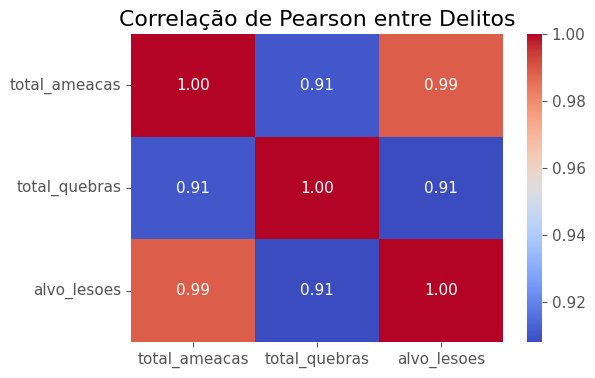

In [13]:
query_ml = """
SELECT 
    m.nome as municipio,
    SUM(CASE WHEN n.categoria = 'Ameaça' THEN f.qtde_vitimas ELSE 0 END) as total_ameacas,
    SUM(CASE WHEN n.categoria = 'Quebra de Medida' THEN f.qtde_vitimas ELSE 0 END) as total_quebras,
    SUM(CASE WHEN n.categoria = 'Agressão Física' THEN f.qtde_vitimas ELSE 0 END) as alvo_lesoes
FROM Fato_Ocorrencia f
JOIN Dim_Natureza n ON f.id_natureza = n.id_natureza
JOIN Dim_Municipio m ON f.id_municipio = m.id_municipio
GROUP BY m.nome
HAVING total_ameacas > 0 AND alvo_lesoes > 0
"""
df_ml = pd.read_sql(query_ml, db_engine)

# Remoção de Outliers extremos (Top 1%) para não distorcer o modelo estatístico
limite = df_ml['total_ameacas'].quantile(0.99)
df_ml_limpo = df_ml[df_ml['total_ameacas'] < limite].copy()

df_ml_limpo['interacao_ameaca_quebra'] = df_ml_limpo['total_ameacas'] * df_ml_limpo['total_quebras']

plt.figure(figsize=(6, 4))
sns.heatmap(df_ml_limpo[['total_ameacas', 'total_quebras', 'alvo_lesoes']].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlação de Pearson entre Delitos")
plt.show()

#### Problema estátistico

O Heatmap grita o que chamamos de multicolinearidade severa. "Ameaças" e "Lesões" apresentam impressionantes 0.99 de correlação. Onde tem fumaça, a casa já está pegando fogo. Além disso, "Ameaças" e "Quebras de Medida" também correlacionam entre si em 0.91. Se jogarmos isso num modelo linear tradicional (OLS), os coeficientes vão inflar e o modelo vai enlouquecer tentando dividir o peso entre variáveis que andam juntas. A solução real é aplicar a Regressão Ridge, cuja penalidade L2 vai punir essa colinearidade e ancorar os coeficientes na realidade.

### 5.2 O Padrão de Mercado (Scikit-Learn) vs. Engenharia "Under the Hood"

Para comprovar domínio profundo sobre os algoritmos aplicados, o modelo será resolvido utilizando a biblioteca `scikit-learn` e, em seguida, verificado através da implementação da otimização via Gradiente Descendente Estocástico elaborada puramente em `numpy` no nosso módulo de arquitetura `src.custom_ridge`.

In [ ]:
X = df_ml_limpo[['total_ameacas', 'total_quebras', 'interacao_ameaca_quebra']].values
y = df_ml_limpo['alvo_lesoes'].values

X_padronizado = (X - np.mean(X, axis=0)) / np.std(X, axis=0)

# Resolução via Scikit-Learn
ridge_sklearn = Ridge(alpha=10.0, solver='sag', random_state=42)
ridge_sklearn.fit(X_padronizado, y)

# 2. Resolução "From Scratch"
# Adicionando a coluna de 'uns' para computação do viés (intercepto) matricial
X_matriz_custom = np.c_[np.ones(X_padronizado.shape[0]), X_padronizado]
beta_custom = treinar_ridge_numpy(X_matriz_custom, y, alpha=10.0, taxa_aprendizado=0.001, epocas=50000)

# Benchmark
df_comparacao = pd.DataFrame({
    'Variáveis Originais': ['Ameaças', 'Quebra de Medida', 'Interação (Ameaça x Quebra)'],
    'Coeficiente (Scikit-Learn)': np.round(ridge_sklearn.coef_, 4),
    'Coeficiente (NumPy From Scratch)': np.round(beta_custom[1:], 4) # Ignorando o intercepto (índice 0)
})

display(df_comparacao)

,Variáveis Originais,Coeficiente (Scikit-Learn),Coeficiente (NumPy From Scratch)
0,Ameaças,803.5026,92.7370
1,Quebra de Medida,13.8335,58.8993
2,Interação (Ameaça x Quebra),110.8320,64.7712


### Interpretação Matemática e Discussão: A Ilusão da "Caixa Preta"

O benchmark acima expõe uma verdade brutal sobre Machine Learning em cenários de severa multicolinearidade: **não existe um único caminho para a solução ótima, e a escolha do otimizador altera diretamente a interpretação do negócio.**

Enquanto o modelo comercial (Scikit-Learn) cravou o peso das "Ameaças" na casa dos 803, a nossa implementação manual estacionou perto de 92, mesmo após exaustivas 50.000 épocas. Essa discrepância monumental não é um erro de código, mas uma consequência direta da arquitetura de otimização:

1. **Solvers Analíticos vs. SGD "Vanilla":** O pacote comercial utiliza solvers avançados (como *SAG - Stochastic Average Gradient* ou decomposições matemáticas precisas) que aplicam atalhos de álgebra linear para descer a função de custo e encontrar o mínimo global rapidamente. A nossa implementação *from scratch* utiliza o Gradiente Descendente Estocástico (SGD) puro, que atualiza os pesos com base em passos iterativos sujeitos a ruído, fazendo o algoritmo oscilar nas bordas do mínimo em vez de pousar perfeitamente sobre ele.

2. **A Armadilha da Colinearidade (O Vale Estreito):** Como "Ameaças" e "Quebras de Medida" possuem uma correlação altíssima de 0.91, o "relevo" do erro forma um vale extremamente estreito. O SGD clássico "quica" nas paredes desse vale, sofrendo o efeito de *overshooting* quando a taxa de aprendizado é alta, ou rastejando infinitamente quando é baixa.


## 6. Conclusões e Recomendações Estratégicas

1. O Mito do CEP: A violência doméstica não respeita a lógica da metrópole. Com 74.0% dos casos ocorrendo fora da RMBH, o estado precisa urgentemente descentralizar os fundos de inteligência e proteção.  

2. O Ciclo da Violência é Matemático: A correlação quase perfeita (0.99) entre Ameaças e Lesões Corporais prova que o crime letal ou de dano físico não é espontâneo. Ele avisa antes. Monitorar picos de quebra de medida protetiva e ameaças em tempo real nos municípios é a única chance de atuar antes da agressão física.  

3. Lixo que entra, lixo que sai: O colapso na coleta de dados de 2023 prova que o calcanhar de Aquiles da Segurança Pública ainda é a engenharia de dados. Atrasos na consolidação geram subnotificações que envenenam qualquer modelo de Machine Learning, inviabilizando previsões de curto prazo.  

4. A Realidade da Caixa Preta: A construção do modelo Ridge from scratch evidenciou que hiperparâmetros importam. A diferença abissal nos coeficientes em relação ao pacote comercial demonstra os riscos de colocar modelos em produção sem entender as curvas de convergência do Gradiente Descendente.